## Visualizando soluções do modelo de Rosenzweig-MacArthur

O modelo de **Rosenzweig-MacArthur** descreve a dinâmica de interação entre duas populações, presas e predadores, por meio de um sistema de equações diferenciais ordinárias (EDOs).

O modelo considera o crescimento logístico das presas e a predação descrita pela resposta funcional de Holling tipo II:

$$
\begin{cases}
\displaystyle
\frac{dN}{dt}
=
rN\left(1-\frac{N}{K}\right)
-
\frac{aNP}{1+ahN},
\\[10pt]
\displaystyle
\frac{dP}{dt}
=
e\frac{aNP}{1+ahN}
-
mP.
\end{cases}
$$

Em que:

- $N(t)$: população de presas no instante $t$;
- $P(t)$: população de predadores no instante $t$;
- $r$: taxa intrínseca de crescimento das presas;
- $K$: capacidade de suporte do ambiente;
- $a$: taxa de ataque dos predadores;
- $h$: tempo de manipulação das presas;
- $e$: eficiência de conversão de presas consumidas em crescimento dos predadores;
- $m$: taxa de mortalidade dos predadores.

O vetor de parâmetros do modelo é definido por:

$$
\boldsymbol{\theta}=(r,K,a,h,e,m).
$$

As condições iniciais são dadas por:

$$
N(0)=N_0,\qquad P(0)=P_0.
$$

Neste trabalho, o sistema será resolvido numericamente para diferentes configurações de $\boldsymbol{\theta}$, permitindo gerar dados sintéticos e avaliar métodos de identificação de parâmetros.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from data import gerar_dados_sinteticos, rosenzweig_macarthur

In [4]:
# Parâmetros verdadeiros
theta_true = np.array([
    1.0,    # r
    100.0,  # K
    0.05,   # a
    0.2,    # h
    0.5,    # e
    0.5,    # m
])

# Condições iniciais
y0 = [40.0, 10.0]

# Geração do dataset
df = gerar_dados_sinteticos(
    modelo=rosenzweig_macarthur,
    parametros=theta_true,
    y0=y0,
    t_span=(0, 30),
    n_obs=50,
    ruido=0.02,
    seed=2026,
    nomes_variaveis=["N", "P"],
)

print(df.head())

          t      N_obs     N_true      P_obs     P_true
0  0.000000  39.464345  40.000000  10.084497  10.000000
1  0.612245  43.817145  45.097877  12.129530  11.639284
2  1.224490  48.339279  47.908191  13.849798  13.952375
3  1.836735  47.685082  47.895765  17.000709  16.893991
4  2.448980  44.884151  45.064922  20.168612  20.247959


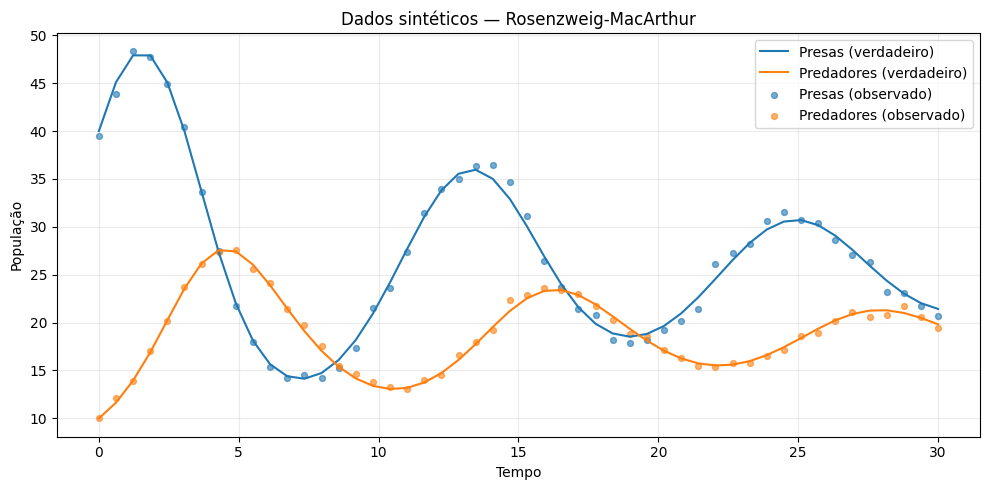

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df["t"], df["N_true"], color="tab:blue", label="Presas (verdadeiro)")

ax.plot(df["t"], df["P_true"], color="tab:orange", label="Predadores (verdadeiro)")

ax.scatter(df["t"], df["N_obs"], color="tab:blue", s=18, alpha=0.6, label="Presas (observado)")

ax.scatter(df["t"], df["P_obs"], color="tab:orange", s=18, alpha=0.6, label="Predadores (observado)")

ax.set_xlabel("Tempo")
ax.set_ylabel("População")
ax.set_title("Dados sintéticos — Rosenzweig-MacArthur")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()